# MEROPS: evidence counts and positional coverage

Inspect Karol's original dictionaries and count matrices before integration. Summarize every indexed dataset, then examine one selected dataset without pooling overlapping memberships.

## Introduction

**Assumptions and notation.** A matrix has shape `(N, P, A)`: code rows, eight positions P4–P4′, and 20 amino acids. `n_cleavages` is the supplied per-code total; positional depth is the sum over the amino-acid axis. Missing positions contribute no observation. Matrices contain marginal counts, so they do not determine the number of distinct full windows or the co-occurrence of residues.

Input: `raw/merops/index.json`, each `codes.json` and `matrices_counts.npy`. Original files remain unchanged. No exports are produced. Migrated scope: count and positional-depth sections of the archived `0_01_merops_matrices.ipynb`; unrelated scoring and clustering analyses are omitted.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src/pep_compass").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data/proteolysis/window_neighbourhood_datasets/raw"
MEROPS = RAW / "merops"
pd.set_option("display.max_columns", None)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Inventory every original dataset without combining overlapping memberships.
index = json.loads((MEROPS / "index.json").read_text())
inventory_rows = []
for key, entry in sorted(index["by_index"].items(), key=lambda item: int(item[0])):
    folder = MEROPS / entry["folder"]
    metadata = json.loads((folder / "codes.json").read_text())
    matrix = np.load(folder / "matrices_counts.npy", allow_pickle=False)  # (N, P, A)
    enzymes = sorted(metadata["peptidases"], key=lambda item: item["row"])
    assert [item["row"] for item in enzymes] == list(range(len(enzymes)))
    assert matrix.shape == (len(enzymes), len(metadata["positions"]), len(metadata["amino_acids"]))
    assert metadata["positions"] == index["positions"]
    assert metadata["amino_acids"] == index["amino_acids"]
    assert np.isfinite(matrix).all() and (matrix >= 0).all()
    inventory_rows.append({
        "dataset_id": int(key), "label": entry["label"], "code_rows": len(enzymes),
        "reported_cleavages": sum(item["n_cleavages"] for item in enzymes),
        "codes_with_any_observation": int((matrix.sum(axis=(1, 2)) > 0).sum()),
    })
inventory = pd.DataFrame(inventory_rows).set_index("dataset_id")
display(inventory)

,label,code_rows,reported_cleavages,codes_with_any_observation
dataset_id,,,,
0,A. baumannii ATCC 19606,35,1584,35
1,E. coli ATCC 11775,91,2008,91
2,E. coli AIG221,91,2008,91
3,E. coli AIG222,91,2008,91
4,K. pneumoniae ATCC 13883,69,1874,68
5,P. aeruginosa PA01,50,1737,49
6,P. aeruginosa PA14,50,1737,49
7,S. aureus ATCC 12600,55,4802,54
8,S. aureus (ATCC BAA-1556) - MRSA,55,4802,54


## Cleavage evidence per named peptidase

Each bar represents one supplied MEROPS code, labelled with its code and name; its length is `n_cleavages` on a logarithmic axis. Colours identify the source serum categories. Vertical lines mark evidence-depth reference values, not inclusion criteria. The threshold table and complete `enzyme_counts` remain available. `TOP_CODES` controls only the displayed bars.

,minimum_cleavages,code_rows,fraction_of_selected_dataset
0,1,55,1.000000
1,5,50,0.909091
2,10,38,0.690909
3,20,29,0.527273
4,50,22,0.400000
5,100,16,0.290909
6,200,9,0.163636
7,500,4,0.072727


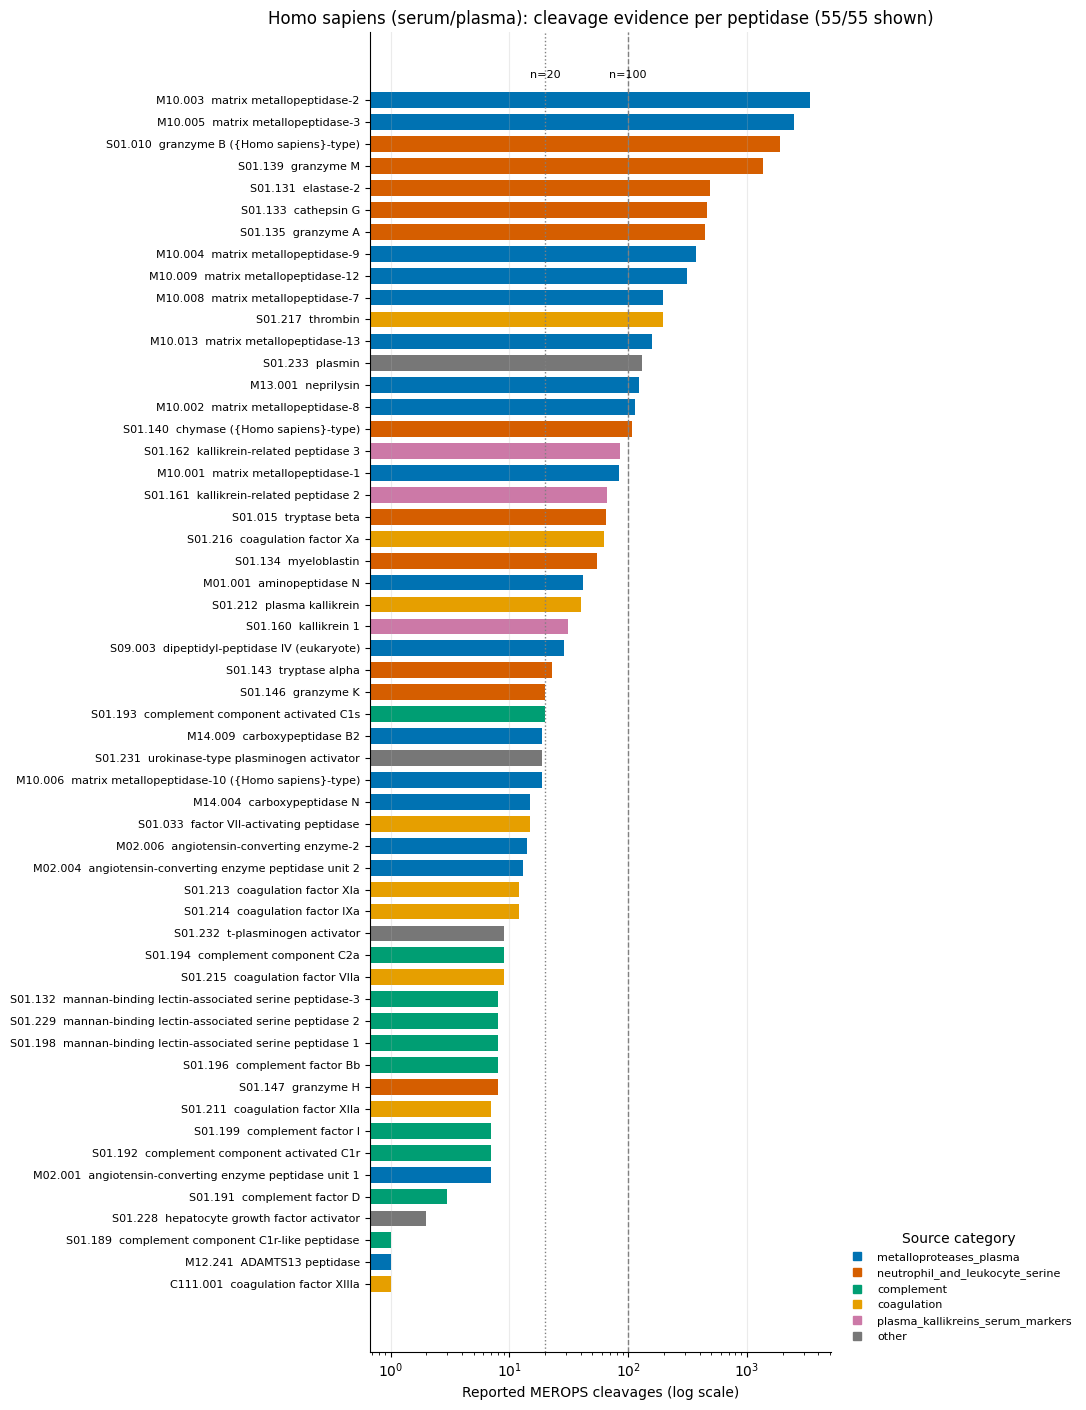

In [3]:
# Select the population and coverage thresholds here.
DATASET_ID = 35
COVERAGE_THRESHOLDS = (1, 5, 10, 20, 50, 100, 200, 500)
FIGURE_SIZE = (7, 3.5)

entry = index["by_index"][str(DATASET_ID)]
folder = MEROPS / entry["folder"]
metadata = json.loads((folder / "codes.json").read_text())
counts = np.load(folder / "matrices_counts.npy", allow_pickle=False)  # (N, P, A)
enzyme_counts = pd.DataFrame(sorted(metadata["peptidases"], key=lambda item: item["row"]))
positions = metadata["positions"]
pooled = enzyme_counts["n_cleavages"].to_numpy(dtype=float)  # (N,)
if np.any(pooled <= 0):
    raise ValueError("Relative coverage requires positive reported cleavage totals")
coverage = pd.DataFrame({
    "minimum_cleavages": COVERAGE_THRESHOLDS,
    "code_rows": [int((pooled >= t).sum()) for t in COVERAGE_THRESHOLDS],
})
coverage["fraction_of_selected_dataset"] = coverage["code_rows"] / len(pooled)
display(coverage)


# Named peptidases, retaining the evidence-depth plot used by the old analysis.
TOP_CODES = 55
REFERENCE_COUNTS = (20, 100)
CATEGORY_COLORS = ("#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7")
ordered = enzyme_counts.sort_values("n_cleavages", ascending=False)
if TOP_CODES is not None:
    ordered = ordered.head(TOP_CODES)
ordered = ordered.iloc[::-1].copy()
categories = enzyme_counts.get("serum_category", pd.Series("unclassified", index=enzyme_counts.index)).fillna("unclassified")
major = list(categories.value_counts().index[:len(CATEGORY_COLORS)])
category_colors = dict(zip(major, CATEGORY_COLORS))
category_colors["other"] = "#777777"
bar_categories = categories.loc[ordered.index].where(categories.loc[ordered.index].isin(major), "other")
FIGURE_SIZE = (11, max(5, 0.24 * len(ordered) + 1))
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.barh(range(len(ordered)), ordered["n_cleavages"],
        color=[category_colors[value] for value in bar_categories], height=0.72)
ax.set_yticks(range(len(ordered)), labels=[f"{row.code}  {row['name']}" for _, row in ordered.iterrows()], fontsize=8)
ax.set(xscale="log", xlabel="Reported MEROPS cleavages (log scale)",
       title=f"{entry['label']}: cleavage evidence per peptidase ({len(ordered)}/{len(enzyme_counts)} shown)")
for threshold in REFERENCE_COUNTS:
    ax.axvline(threshold, color="0.5", linestyle=":" if threshold == REFERENCE_COUNTS[0] else "--", linewidth=1)
    ax.text(threshold, len(ordered), f"n={threshold}", ha="center", fontsize=8)
handles = [plt.Line2D([], [], marker="s", linestyle="", color=category_colors[value], label=value)
           for value in category_colors if value in set(bar_categories)]
ax.legend(handles=handles, title="Source category", loc="lower left", bbox_to_anchor=(1.01, 0), frameon=False, fontsize=8)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## Observations at each position

### Methodology

`depth[n, p] = counts[n, p, :].sum()`; relative coverage divides it by the same code's reported cleavage total. The table retains zero-depth codes. The left figure shows the depth distribution at each position on a `log10(1 + depth)` coordinate, labelled in counts; each dot is one code. The right figure shows the fraction of recorded cleavages represented at each position, again across all selected codes. A value of one means full recorded positional coverage, not a complete substrate sequence.

The complete per-code values remain available in `positional_depth` and `enzyme_counts`. The two panels measure sampling coverage, not residue preference.

,position,total_residue_observations,codes_with_observation,median_depth,median_relative_coverage,codes_above_reported_total
0,P4,12171.0,52,17.0,0.846,0
1,P3,12696.0,52,17.0,0.935,0
2,P2,12907.0,54,18.0,0.992,0
3,P1,13097.0,55,20.0,1.000,0
4,P1p,12851.0,54,19.0,0.900,0
5,P2p,12769.0,51,15.0,0.867,0
6,P3p,12728.0,51,15.0,0.802,0
7,P4p,12632.0,51,15.0,0.756,0


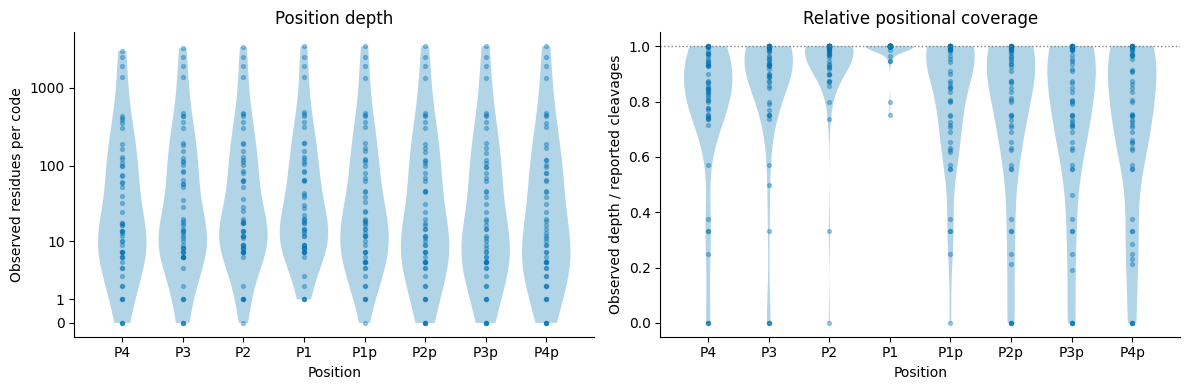

In [4]:
# Figure settings; all selected code rows enter the distributions.
FIGURE_SIZE = (12, 4)
POINT_ALPHA = 0.35
COUNT_TICKS = (0, 1, 10, 100, 1000, 10000)

subsite_depth = counts.sum(axis=-1)  # (N, P)
relative_depth = subsite_depth / pooled[:, None]  # (N, P)
positional_depth = pd.DataFrame(subsite_depth, columns=positions, index=enzyme_counts["code"])
position_summary = pd.DataFrame({
    "position": positions,
    "total_residue_observations": subsite_depth.sum(axis=0),
    "codes_with_observation": (subsite_depth > 0).sum(axis=0),
    "median_depth": np.median(subsite_depth, axis=0),
    "median_relative_coverage": np.median(relative_depth, axis=0),
    "codes_above_reported_total": (subsite_depth > pooled[:, None]).sum(axis=0),
})
display(position_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for ax, values, ylabel, title in (
    (axes[0], np.log10(1 + subsite_depth), "Observed residues per code", "Position depth"),
    (axes[1], relative_depth, "Observed depth / reported cleavages", "Relative positional coverage"),
):
    # Constant columns have no continuous density; show their actual points only.
    for position in range(len(positions)):
        sample = values[:, position]  # (N,)
        if np.ptp(sample) > 0:
            violin = ax.violinplot(sample, positions=[position], widths=0.8, showextrema=False)
            violin["bodies"][0].set_facecolor("#0072B2")
        ax.scatter(np.full(len(sample), position), sample, s=8, alpha=POINT_ALPHA, color="#0072B2")
    ax.set(xticks=range(len(positions)), xticklabels=positions, xlabel="Position", ylabel=ylabel, title=title)
visible_ticks = [x for x in COUNT_TICKS if x <= subsite_depth.max() * 1.1]
axes[0].set_yticks(np.log10(1 + np.asarray(visible_ticks)), labels=visible_ticks)
axes[1].axhline(1, color="0.5", linestyle=":", linewidth=1)
fig.tight_layout()
plt.show()

## Positional coverage and observed versus possible observations

The left panel restores the original positional boxplots: each distribution contains the fraction of each code's reported cleavages observed at that position; the blue line marks the median. The right panel shows one point per code: reported cleavage total (x), mean depth over all eight positions (y), and mean relative coverage (colour). Both axes use logarithmic scales. The dotted diagonal represents complete positional coverage. These are the same selected code rows used by the violins above.

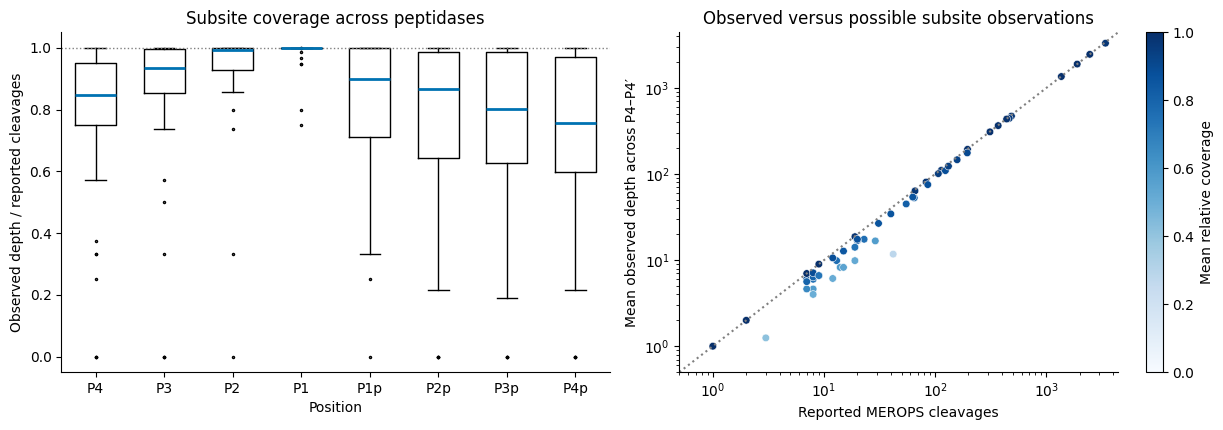

In [5]:
# Plot settings; retain all selected code rows.
FIGURE_SIZE = (12.5, 4.4)
BOX_MEDIAN_COLOR = "#0072B2"

mean_depth = subsite_depth.mean(axis=1)  # (N,)
mean_relative = relative_depth.mean(axis=1)  # (N,)
fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE)
axes[0].boxplot([relative_depth[:, i] for i in range(len(positions))],
                positions=np.arange(len(positions)), widths=0.6,
                medianprops={"color": BOX_MEDIAN_COLOR, "linewidth": 2},
                flierprops={"marker": ".", "markersize": 3})
axes[0].set(xticks=range(len(positions)), xticklabels=positions,
            xlabel="Position", ylabel="Observed depth / reported cleavages",
            title="Subsite coverage across peptidases")
axes[0].axhline(1, color="0.5", linestyle=":", linewidth=1)
positive = mean_depth > 0
image = axes[1].scatter(pooled[positive], mean_depth[positive], c=mean_relative[positive],
                        cmap="Blues", vmin=0, vmax=1, s=30, edgecolor="white", linewidth=0.4)
limits = (max(0.5, min(pooled.min(), mean_depth[positive].min()) * 0.8), pooled.max() * 1.3)
axes[1].plot(limits, limits, linestyle=":", color="0.5")
axes[1].set(xscale="log", yscale="log", xlim=limits, ylim=limits,
            xlabel="Reported MEROPS cleavages", ylabel="Mean observed depth across P4–P4′",
            title="Observed versus possible subsite observations")
fig.colorbar(image, ax=axes[1], label="Mean relative coverage")
fig.tight_layout()
plt.show()

## Human dataset versus its serum/plasma subset

Load original dataset 34 (human) and 35 (serum/plasma), joining by supplied MEROPS code. The serum population is a curated subset of the human population; it is not an independent serum cleavage experiment. Count and matrix equality for shared codes are checked. Statistics are descriptive: no test treats these overlapping populations as independent.

The summary includes the human population, serum subset, and the disjoint human remainder. Counts are inherited from MEROPS and do not establish physiological serum activity. The positional table reports actual residue observations, rather than replacing them with normalized probabilities.

In [6]:
# Original population definitions, not new biological filters.
HUMAN_DATASET_ID = 34
SERUM_DATASET_ID = 35
populations = {}
for dataset_id, label in ((HUMAN_DATASET_ID, "Human (all)"), (SERUM_DATASET_ID, "Serum/plasma")):
    source_folder = MEROPS / index["by_index"][str(dataset_id)]["folder"]
    source_metadata = json.loads((source_folder / "codes.json").read_text())
    frame = pd.DataFrame(sorted(source_metadata["peptidases"], key=lambda item: item["row"]))
    matrix = np.load(source_folder / "matrices_counts.npy", allow_pickle=False)  # (N_group, P, A)
    assert source_metadata["positions"] == positions
    assert source_metadata["amino_acids"] == metadata["amino_acids"]
    populations[label] = (frame, matrix)
human_frame, human_counts = populations["Human (all)"]
serum_frame, serum_counts = populations["Serum/plasma"]
human_row_by_code = human_frame.set_index("code")["row"]
assert set(serum_frame["code"]).issubset(set(human_frame["code"]))
for _, row in serum_frame.iterrows():
    human_row = int(human_row_by_code[row["code"]])
    assert row["n_cleavages"] == human_frame.iloc[human_row]["n_cleavages"]
    assert np.array_equal(serum_counts[int(row["row"])], human_counts[human_row])
remainder_mask = ~human_frame["code"].isin(serum_frame["code"])
populations["Human outside serum"] = (human_frame.loc[remainder_mask], human_counts[remainder_mask])
summary_rows, position_rows = [], []
for label, (frame, matrix) in populations.items():
    totals = frame["n_cleavages"].to_numpy(dtype=float)  # (N_group,)
    depths = matrix.sum(axis=-1)  # (N_group, P)
    summary_rows.append({
        "population": label, "code_rows": len(frame), "reported_cleavages": int(totals.sum()),
        "median_cleavages_per_code": np.median(totals), "p10": np.quantile(totals, 0.1),
        "p90": np.quantile(totals, 0.9), "minimum": totals.min(), "maximum": totals.max(),
        "codes_below_10": int((totals < 10).sum()), "codes_at_least_100": int((totals >= 100).sum()),
    })
    for i, position in enumerate(positions):
        position_rows.append({
            "population": label, "position": position,
            "residue_observations": int(depths[:, i].sum()),
            "median_depth_per_code": np.median(depths[:, i]),
            "pooled_coverage_fraction": depths[:, i].sum() / totals.sum(),
        })
human_serum_summary = pd.DataFrame(summary_rows).set_index("population")
human_serum_positions = pd.DataFrame(position_rows)
display(human_serum_summary.round(2))
display(human_serum_positions.pivot(index="position", columns="population", values="residue_observations").reindex(positions))

,code_rows,reported_cleavages,median_cleavages_per_code,p10,p90,minimum,maximum,codes_below_10,codes_at_least_100
population,,,,,,,,,
Human (all),390,44583,9.0,1.0,158.4,1.0,3417.0,197,62
Serum/plasma,55,13121,20.0,7.0,455.4,1.0,3417.0,17,16
Human outside serum,335,31462,8.0,1.0,124.6,1.0,3126.0,180,46


population,Human (all),Human outside serum,Serum/plasma
position,,,
P4,40995,28824,12171
P3,42346,29650,12696
P2,43111,30204,12907
P1,44488,31391,13097
P1p,43609,30758,12851
P2p,42979,30210,12769
P3p,42703,29975,12728
P4p,42203,29571,12632


### Comparison figures

The left panel gives the total number of observed residues at every position, including partial windows, for the full human population and its serum subset. The right panel compares relative positional coverage across code rows in two **disjoint** groups: serum versus human outside serum. Each violin uses all code rows in its group; each dot is one code. The remainder is used here to avoid duplicating serum codes between the two distributions.

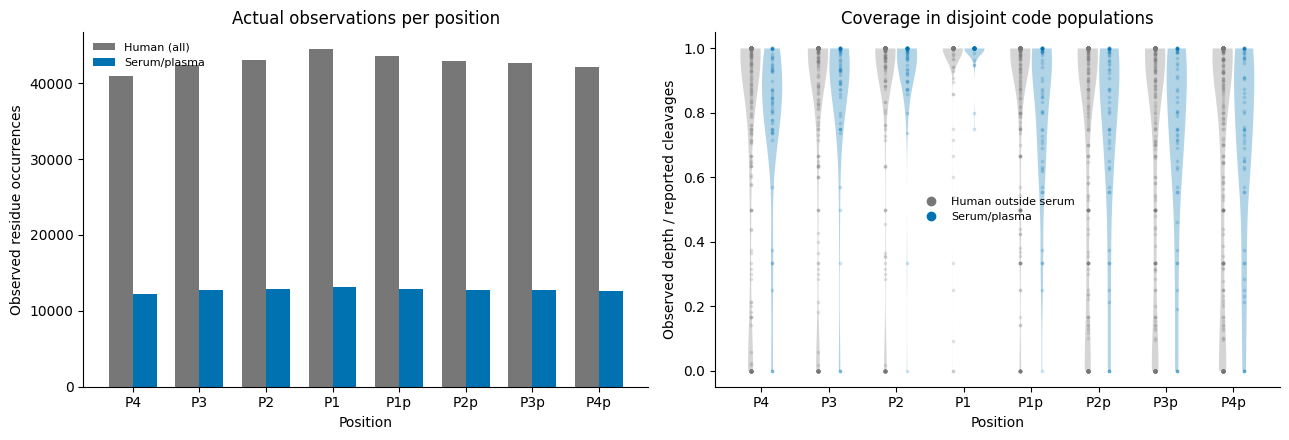

In [7]:
# Counts use the overlapping populations explicitly; distributions use disjoint groups.
COUNT_POPULATIONS = ("Human (all)", "Serum/plasma")
DISTRIBUTION_POPULATIONS = ("Human outside serum", "Serum/plasma")
COLORS = ("#777777", "#0072B2")
FIGURE_SIZE = (13, 4.5)

fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE)
x = np.arange(len(positions))  # (P,)
for group, label in enumerate(COUNT_POPULATIONS):
    values = human_serum_positions.loc[human_serum_positions["population"].eq(label)].set_index("position").loc[positions, "residue_observations"]
    axes[0].bar(x + (group - 0.5) * 0.36, values, width=0.36, color=COLORS[group], label=label)
axes[0].set(xticks=x, xticklabels=positions, xlabel="Position", ylabel="Observed residue occurrences", title="Actual observations per position")
axes[0].legend(frameon=False, fontsize=8)
for group, label in enumerate(DISTRIBUTION_POPULATIONS):
    frame, matrix = populations[label]
    relative = matrix.sum(axis=-1) / frame["n_cleavages"].to_numpy()[:, None]  # (N_group, P)
    for i in range(len(positions)):
        values = relative[:, i]  # (N_group,)
        location = i + (group - 0.5) * 0.32
        if np.ptp(values) > 0:
            violin = axes[1].violinplot(values, positions=[location], widths=0.3, showextrema=False)
            violin["bodies"][0].set_facecolor(COLORS[group])
        axes[1].scatter(np.full(len(values), location), values, s=3, alpha=0.15, color=COLORS[group])
axes[1].set(xticks=x, xticklabels=positions, xlabel="Position", ylabel="Observed depth / reported cleavages", title="Coverage in disjoint code populations")
axes[1].legend(handles=[plt.Line2D([], [], color=color, marker="o", linestyle="", label=label)
                        for color, label in zip(COLORS, DISTRIBUTION_POPULATIONS)], frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### Remarks

Dataset rows overlap: the same supplied matrix may occur in several indexed populations. Do not add dataset totals to obtain independent events. Positional marginals cannot reconstruct unique cleavage windows. No serum-specific biological or kinetic filter is applied to the supplied panel.

### Notes

## Results / Summary

### LLM

The inventory contains 36 indexed datasets. The original human dataset has 390 code rows and 44,583 reported cleavages; the serum/plasma subset has 55 code rows and 13,121 reported cleavages. These populations overlap and their totals must not be added.

The inventory covers all indexed populations; the two subsequent figures use the explicit `DATASET_ID`. Count distributions and positional missingness must be retained when these data are integrated.

### Person

## Common numerical parameters

The common output is a positional probability matrix: each amino-acid column is its count divided by the observed positional total. Original overlapping profile populations remain separate. All transformations stay in memory; no CSV or database is written.

In [8]:
# Use the independent data library from this checkout.
import sys
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.merge import (
    build_dataset, parse_dataset, add_merops_scores,
)
# Keep the overlapping human and serum profile populations separately identified.
contract = parse_dataset("merops", ROOT / "data/proteolysis", data=[34, 35])
probabilities = contract.position_probabilities()
display(probabilities[["source_db", "source_dataset", "merops_code", "position", "observed_weight", "A", "G", "L", "P"]].head(8))


,source_db,source_dataset,merops_code,position,observed_weight,A,G,L,P
0,merops,34,C14.003,P4,684.0,0.046784,0.035088,0.036550,0.008772
1,merops,34,C14.003,P3,693.0,0.054834,0.036075,0.103896,0.008658
2,merops,34,C14.003,P2,696.0,0.045977,0.021552,0.116379,0.116379
3,merops,34,C14.003,P1,700.0,0.004286,0.000000,0.001429,0.000000
4,merops,34,C14.003,P1p,697.0,0.142037,0.317073,0.031564,0.008608
5,merops,34,C14.003,P2p,697.0,0.134864,0.111908,0.080344,0.067432
6,merops,34,C14.003,P3p,696.0,0.086207,0.089080,0.091954,0.047414
7,merops,34,C14.003,P4p,695.0,0.090647,0.123741,0.058993,0.053237
